# Part 2 — Train, compare, and test the detector

In this notebook, you will train the complete detector and conduct controlled
experiments. You will:

1. train a baseline model and report its validation result;
2. compare three settings of one training hyperparameter;
3. change one aspect of the model architecture;
4. select a model using validation results and evaluate it once on the test set;
5. visualize and analyze several predictions.

Record your results and explanations in [`report.md`](report.md). Do not use
the test set to select a model or tune a threshold.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import os

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import torch

import assignment2 as a2

DATASET_ROOT = "./data/VMRD_COCO"
try:
    import torch_directml
    DEVICE = torch_directml.device()
except ImportError:
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 519
BATCH_SIZE = 4
NUM_EPOCHS = 25

train_loader = a2.get_train_loader(DATASET_ROOT, BATCH_SIZE)
val_loader = a2.get_val_loader(DATASET_ROOT, BATCH_SIZE)

print("Device:", DEVICE)
print("Training images:", len(train_loader.dataset))
print("Validation images:", len(val_loader.dataset))

Device: privateuseone:0
Training images: 1162
Validation images: 291


## 1. Baseline model

You have now implemented the Dataset, detector, loss, training loop, and
evaluation loop. The following cell puts these pieces together to train the
baseline model.

Use the following baseline settings:

- model: `ResNet9Detector` with skip connections;
- batch size: `32`;
- number of epochs: `25`;
- optimizer: `AdamW` with `lr=2.5e-3` and `weight_decay=1e-4`;
- scheduler: `OneCycleLR` with `max_lr=2.5e-3`,
  `steps_per_epoch=len(train_loader)`, and `pct_start=0.15`.

Run the provided cell. In your report, record the validation losses,
precision, and recall; include the training-loss curve; and briefly describe
the training behaviour. This baseline is the reference for the controlled
experiments below.


c:\Repos\ENSF519_01\ENSF519_assignment2_template\ENSF519_assignment2_template\.venv\Lib\site-packages\torch\nn\functional.py:3244: UserWarning: The operator 'aten::log_sigmoid_forward' is not currently supported on the DML backend and will fall back to run on the CPU. This may have performance implications. (Triggered internally at C:\__w\1\s\pytorch-directml-plugin\torch_directml\csrc\dml\dml_cpu_fallback.cpp:17.)
  return torch.binary_cross_entropy_with_logits(input, target, weight, pos_weight, reduction_enum)


Validation total_loss: 1.8384
Validation objectness_loss: 0.4735
Validation class_loss: 0.7493
Validation box_loss: 0.3078
Validation precision: 0.668
Validation recall:    0.654


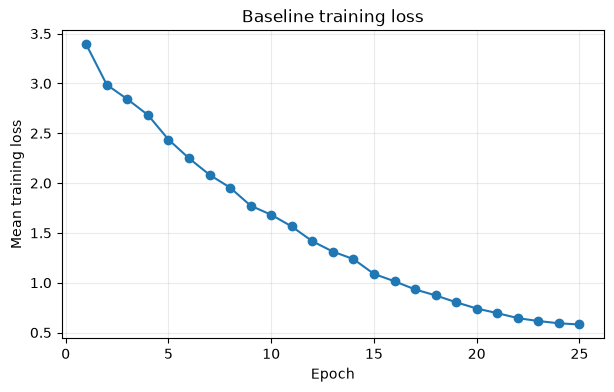

In [2]:
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

baseline_model = a2.ResNet9Detector().to(DEVICE)
baseline_history = a2.train_detection_model(
    baseline_model,
    train_loader,
    num_epochs=NUM_EPOCHS,
    device=DEVICE,
)
baseline_val_losses, baseline_val_accuracy = a2.evaluate_detection_model(
    baseline_model, val_loader, DEVICE
)

for name, value in baseline_val_losses.items():
    print(f"Validation {name}: {value:.4f}")
print(f"Validation precision: {baseline_val_accuracy['precision']:.3f}")
print(f"Validation recall:    {baseline_val_accuracy['recall']:.3f}")

batches_per_epoch = len(train_loader)
baseline_epoch_loss = np.array(
    baseline_history["total_loss"]
).reshape(NUM_EPOCHS, batches_per_epoch).mean(axis=1)
plt.figure(figsize=(7, 4))
plt.plot(
    range(1, NUM_EPOCHS + 1),
    baseline_epoch_loss,
    marker="o",
)
plt.xlabel("Epoch")
plt.ylabel("Mean training loss")
plt.title("Baseline training loss")
plt.grid(alpha=0.25)
plt.show()

baseline_model = baseline_model.to("cpu")
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## 2. Change one training hyperparameter

Modify **one** training aspect, such as:
- batch size
- learning rate
- optimizer type or hyperparameters
- scheduler type or hyperparameters

Compare the baseline setting with **two** alternative settings.
Only change one aspect at a time so that the comparison is fair.

Report the validation results and plot all three training-loss curves. Explain how the selected hyperparameter affected convergence and validation performance. If the performance does not change, this is also a valid observation, explain why you think that is the case.

== baseline ==
  Validation total_loss: 1.8384
  Validation objectness_loss: 0.4735
  Validation class_loss: 0.7493
  Validation box_loss: 0.3078
  Validation precision: 0.668
  Validation recall:    0.654
== lr_1e-3 ==
  Validation total_loss: 1.9130
  Validation objectness_loss: 0.5995
  Validation class_loss: 0.7278
  Validation box_loss: 0.2928
  Validation precision: 0.781
  Validation recall:    0.606
== lr_5e-3 ==
  Validation total_loss: 1.9931
  Validation objectness_loss: 0.4614
  Validation class_loss: 0.8653
  Validation box_loss: 0.3332
  Validation precision: 0.578
  Validation recall:    0.615


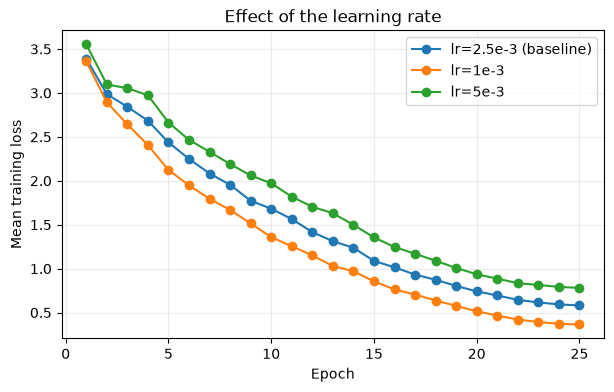

In [3]:
# Controlled experiment: learning rate (baseline 2.5e-3 vs 1e-3 and 5e-3).
# Everything else (data, seed, model, epochs, batch size) stays identical.
def run_experiment(name, model_kwargs=None, lr=2.5e-3):
    torch.manual_seed(SEED)
    model = a2.ResNet9Detector(**(model_kwargs or {})).to(DEVICE)
    history = a2.train_detection_model(
        model, train_loader, num_epochs=NUM_EPOCHS, device=DEVICE,
        optimizer_kwargs={"lr": lr}, scheduler_kwargs={"max_lr": lr},
    )
    val_losses, val_accuracy = a2.evaluate_detection_model(
        model, val_loader, DEVICE
    )
    model = model.to("cpu")  # free GPU memory for the next run
    torch.save(model.state_dict(), f"{name}.pt")  # survive a kernel crash
    return {"model": model, "history": history,
            "val_losses": val_losses, "val_accuracy": val_accuracy}


def epoch_curve(history):
    return np.array(history["total_loss"]).reshape(
        NUM_EPOCHS, len(train_loader)
    ).mean(axis=1)


def print_result(name, result):
    print(f"== {name} ==")
    for key, value in result["val_losses"].items():
        print(f"  Validation {key}: {value:.4f}")
    print(f"  Validation precision: {result['val_accuracy']['precision']:.3f}")
    print(f"  Validation recall:    {result['val_accuracy']['recall']:.3f}")


results = {"baseline": {
    "model": baseline_model, "history": baseline_history,
    "val_losses": baseline_val_losses, "val_accuracy": baseline_val_accuracy,
}}
results["lr_1e-3"] = run_experiment("lr_1e-3", lr=1e-3)
results["lr_5e-3"] = run_experiment("lr_5e-3", lr=5e-3)

for name in ("baseline", "lr_1e-3", "lr_5e-3"):
    print_result(name, results[name])

plt.figure(figsize=(7, 4))
for name, label in [("baseline", "lr=2.5e-3 (baseline)"),
                    ("lr_1e-3", "lr=1e-3"), ("lr_5e-3", "lr=5e-3")]:
    plt.plot(range(1, NUM_EPOCHS + 1), epoch_curve(results[name]["history"]),
             marker="o", label=label)
plt.xlabel("Epoch")
plt.ylabel("Mean training loss")
plt.title("Effect of the learning rate")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 3. Change one aspect of the model

Modify the model by changing one architectural aspect. Choose **one**
architectural aspect and make one controlled change. Examples include:

- removing or adding skip connections;
- removing normalization or changing the normalization layer;
- adding or removing a layer;
- changing a layer parameter;
- adding dropout.

Keep the data split and training settings identical to the baseline. Report the
validation result, compare the loss curves, and explain why the change may have
helped or hurt performance.

You may use an optional model setting through `**kwargs`, or directly modify
`assignment2/model.py`. For example, the optional `use_skip` setting can
be used to compare the baseline with a model without skip connections.

== baseline ==
  Validation total_loss: 1.8384
  Validation objectness_loss: 0.4735
  Validation class_loss: 0.7493
  Validation box_loss: 0.3078
  Validation precision: 0.668
  Validation recall:    0.654
== no_skip ==
  Validation total_loss: 2.1106
  Validation objectness_loss: 0.5765
  Validation class_loss: 0.8951
  Validation box_loss: 0.3195
  Validation precision: 0.660
  Validation recall:    0.588


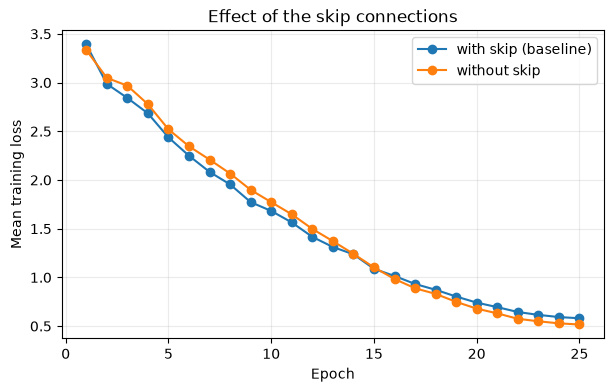

In [4]:
# Controlled experiment: remove the skip connections (everything else equal).
results["no_skip"] = run_experiment("no_skip", model_kwargs={"use_skip": False})
print_result("baseline", results["baseline"])
print_result("no_skip", results["no_skip"])

plt.figure(figsize=(7, 4))
for name, label in [("baseline", "with skip (baseline)"),
                    ("no_skip", "without skip")]:
    plt.plot(range(1, NUM_EPOCHS + 1), epoch_curve(results[name]["history"]),
             marker="o", label=label)
plt.xlabel("Epoch")
plt.ylabel("Mean training loss")
plt.title("Effect of the skip connections")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 4. Select a model and evaluate the test set

Select a model using **validation results only**. Consider validation loss,
precision, recall, and the tradeoff between precision and recall. You may
choose one of the models above or train one additional model based on what you
learned. Clearly justify your choice in the report.

After making the decision, evaluate the selected model on the test set exactly
once. Report the final test loss, precision, and recall. Do not go back and
change the model or score threshold based on the test result.


In [5]:
# Select using validation results only: lowest validation total loss.
# Compare precision/recall in the printed tables and justify it in report.md.
selected_name = min(results, key=lambda k: results[k]["val_losses"]["total_loss"])
print("Selected model:", selected_name)
selected_model = results[selected_name]["model"]

# Evaluate on the test set exactly once.
test_loader = a2.get_test_loader(DATASET_ROOT, BATCH_SIZE)
test_losses, test_accuracy = a2.evaluate_detection_model(
    selected_model.to(DEVICE), test_loader, DEVICE
)
for name, value in test_losses.items():
    print(f"Test {name}: {value:.4f}")
print(f"Test precision: {test_accuracy['precision']:.3f}")
print(f"Test recall:    {test_accuracy['recall']:.3f}")

Selected model: baseline
Test total_loss: 1.8751
Test objectness_loss: 0.4724
Test class_loss: 0.7734
Test box_loss: 0.3147
Test precision: 0.709
Test recall:    0.663


## 5. Visualize and analyze predictions

Visualize several test images with both ground-truth and predicted boxes. The
examples do not need to be failures. In the report, discuss what the detector
does well, what errors or limitations you observe, and at least one reasonable
way to improve it.

Dashed red boxes below are ground truth. Solid colored boxes are predictions
after non-maximum suppression. You may adjust the visualization score threshold
for readability, but do not use test images to tune the model itself.

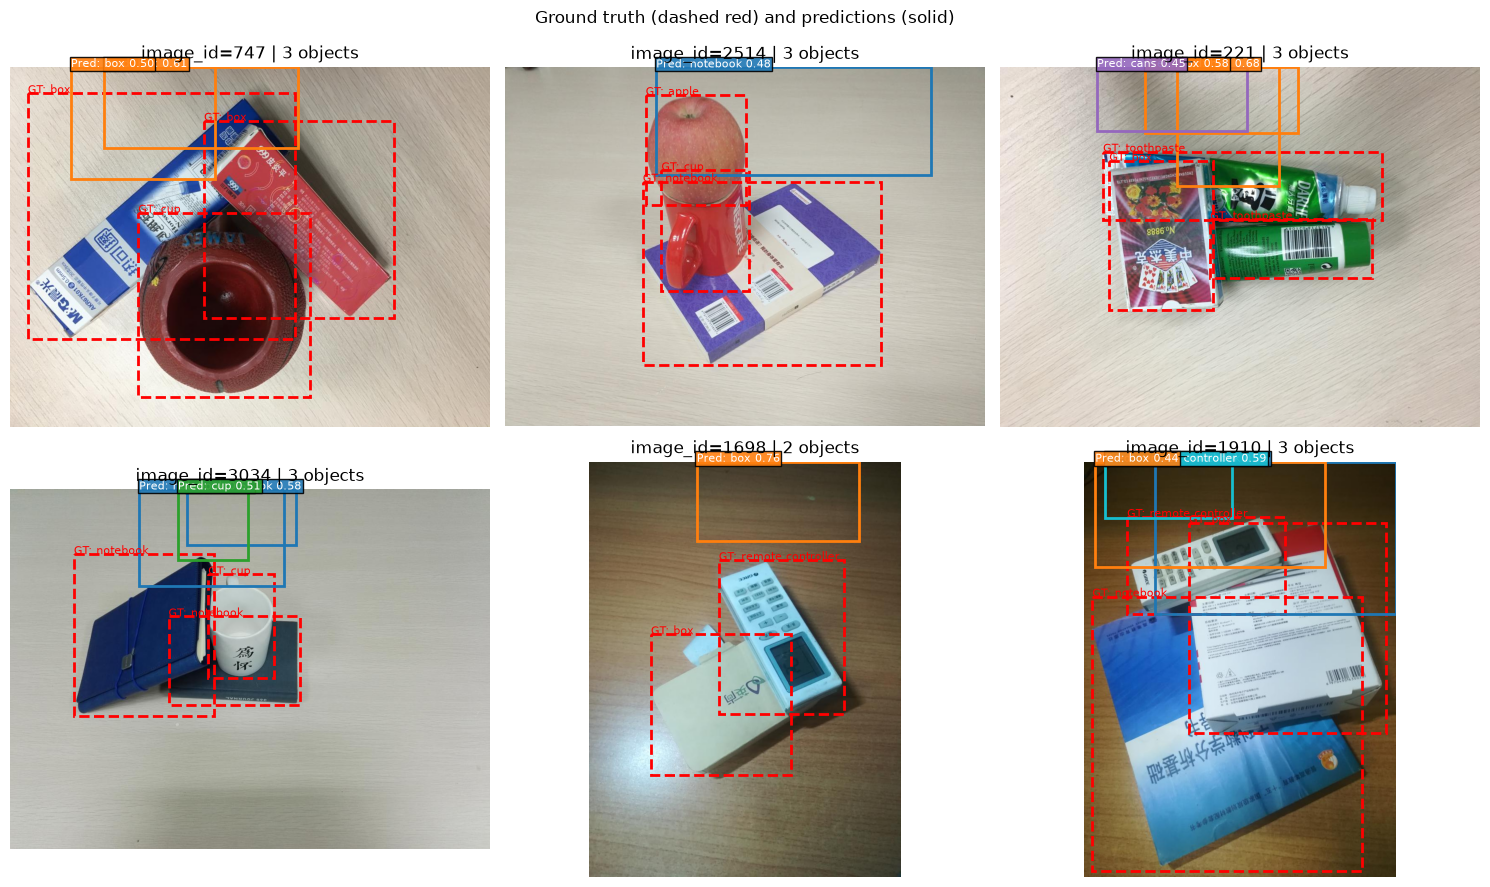

In [6]:
from PIL import Image

# `selected_model` comes from your model-selection experiment above. If you
# restarted the kernel, restore or retrain that model before running this cell.
selected_model = selected_model.to(DEVICE)
selected_model.eval()

test_loader = a2.get_test_loader(DATASET_ROOT, BATCH_SIZE)
test_annotations = json.load(open(os.path.join(
    DATASET_ROOT, "annotations", "instances_test.json"
)))
category_names = {
    category["id"]: category["name"]
    for category in test_annotations["categories"]
}

# Randomly choose several image records, as in notebook 00.
num_examples = min(6, len(test_annotations["images"]))
example_indices = np.random.default_rng(SEED).choice(
    len(test_annotations["images"]),
    size=num_examples,
    replace=False,
)
example_tensors = torch.stack([
    test_loader.dataset[int(index)][0]
    for index in example_indices
])

with torch.no_grad():
    logits = selected_model(example_tensors.to(DEVICE))
predictions = a2.decode_predictions(
    logits,
    score_threshold=0.40,
    nms_iou_threshold=0.50,
)
colors = plt.get_cmap("tab10")

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis, dataset_index, prediction in zip(
    axes.flat, example_indices, predictions
):
    image_info = test_annotations["images"][int(dataset_index)]
    image_id = image_info["id"]
    image_annotations = [
        annotation for annotation in test_annotations["annotations"]
        if annotation["image_id"] == image_id
    ]

    image_path = os.path.join(
        DATASET_ROOT, "images", "test", image_info["file_name"]
    )
    image = Image.open(image_path).convert("RGB")
    width, height = image.size
    axis.imshow(image)

    # Plot the ground-truth annotations using the visualization from notebook 00.
    for annotation in image_annotations:
        x, y, box_width, box_height = annotation["bbox"]
        axis.add_patch(Rectangle(
            (x, y),
            box_width,
            box_height,
            fill=False,
            edgecolor="red",
            linestyle="--",
            linewidth=2,
        ))
        axis.text(
            x,
            y,
            f"GT: {category_names[annotation['category_id']]}",
            color="red",
            fontsize=8,
        )

    # Add the selected model's predictions to the same image.
    for box, score, label in zip(
        prediction["boxes"],
        prediction["scores"],
        prediction["labels"],
    ):
        x1, y1, x2, y2 = box.tolist()
        color = colors(int(label) % 10)
        axis.add_patch(Rectangle(
            (x1 * width, y1 * height),
            (x2 - x1) * width,
            (y2 - y1) * height,
            fill=False,
            edgecolor=color,
            linewidth=2,
        ))
        axis.text(
            x1 * width,
            max(0, y1 * height - 12),
            f"Pred: {category_names[int(label) + 1]} {float(score):.2f}",
            color="white",
            fontsize=8,
            bbox={"facecolor": color, "alpha": 0.9, "pad": 1},
        )

    axis.set_title(f"image_id={image_id} | {len(image_annotations)} objects")
    axis.axis("off")

for axis in axes.flat[num_examples:]:
    axis.axis("off")

fig.suptitle("Ground truth (dashed red) and predictions (solid)")
plt.tight_layout()
plt.show()